# Idea 1 - The Second Half of the Chessboard

**The claim (Second Machine Age, ch. 3).** Digital progress is *exponential*, and
the human mind is "inept at understanding exponential growth." Steady doubling
has carried us into the second half of the chessboard, "a time when what came
before is no longer a reliable guide to what will happen next."

**What we can actually test.** Moore's Law is a statement about components per
chip, which no statistical agency measures. What the national accounts *do*
measure is the quality-adjusted price of computing equipment: BEA's hedonic
price indexes hold performance constant, so a falling index is exactly
"more power per dollar." That makes the book's claim a testable proposition
about a price series:

1. Is the decline log-linear (a straight line on a log axis) over 60+ years?
2. Is it unique to computing, or do other capital goods do the same?
3. Is the *rate* constant - or has the exponent itself changed?
4. How many halvings have we actually banked, i.e. which square are we on?
5. Did quantity respond the way a demand curve says it should?

Question 3 is where this stops being a victory lap. If the exponent broke, the
chapter's forward-looking claim needs qualifying, and that qualification is
worth more to the article than another straight line.

**Data.** BEA NIPA Table 5.3.4 (price indexes for private fixed investment by
type) and Table 5.3.3 (quantity indexes), annual, full history. FRED `GDPDEF`
for the economy-wide price level, so we can separate "computers got cheaper"
from "everything got more expensive."

In [8]:
import sys, pathlib, warnings, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# make common/stacklib.py importable no matter where the kernel started
_here = pathlib.Path.cwd()
for _cand in [_here, *_here.parents]:
    if (_cand / "common" / "stacklib.py").exists():
        sys.path.insert(0, str(_cand / "common"))
        break
import importlib
import stacklib as sl
importlib.reload(sl)      # pick up edits to common/stacklib.py without a kernel restart

warnings.filterwarnings("ignore", category=FutureWarning)
print("stacklib version:", sl.__version__)

DIRS = sl.dirs_for("01_second_half_of_the_chessboard")
KEYS = sl.load_keys()
sl.apply_theme()

BASE_YEAR = 1970          # rebase everything here; the book's charts start ~1970
BREAK_YEAR = 2005         # candidate structural break, tested rather than assumed
print("idea folder:", DIRS["idea"])

stacklib version: 0.2.0
Keys loaded from .env: BEA, BLS, CENSUS, FRED
idea folder: C:\Users\91838\Downloads\Stack_Article\01_second_half_of_the_chessboard


## 1. Pull the BEA price and quantity indexes

The first call prints every line description in the table. If a label below
fails to match, the notebook prints the full list and stops - so we fix the
regex rather than silently charting the wrong line.

In [9]:
prices_raw = sl.bea_nipa_table("T50304", sl.require(KEYS, "BEA"),
                               frequency="A", cache_dir=DIRS["data"])
quant_raw = sl.bea_nipa_table("T50303", sl.require(KEYS, "BEA"),
                              frequency="A", cache_dir=DIRS["data"])

print("\nLines available in Table 5.3.4:")
for _, row in prices_raw[["line", "description"]].drop_duplicates().iterrows():
    print("   %4d  %s" % (row["line"], row["description"]))

BEA T50304: reading cache bea_T50304_A.csv
BEA T50303: reading cache bea_T50303_A.csv

Lines available in Table 5.3.4:
      1  Private fixed investment
      2  Nonresidential
      3  Structures
      4  Commercial and health care
      5  Manufacturing
      6  Power and communication
      7  Mining exploration, shafts, and wells
      8  Other structures
      9  Equipment
     10  Information processing equipment
     11  Computers and peripheral equipment
     12  Other
     13  Industrial equipment
     14  Transportation equipment
     15  Other equipment
     16  Intellectual property products
     17  Software
     18  Research and development
     19  Entertainment, literary, and artistic originals
     20  Residential
     21  Structures
     22  Permanent site
     23  Single family
     24  Multifamily
     25  Other structures
     26  Equipment
     27  Private fixed investment in structures
     28  Private fixed investment in new structures
     29  Nonresidential st

In [10]:
# Table 5.3.4 has no communication-equipment line. Under "Information
# processing equipment" (line 10) BEA gives only "Computers and peripheral
# equipment" (11) and a residual "Other" (12) -- the communication, medical and
# instruments bucket. Addressing lines by number is unambiguous now that the
# table is printed; "Structures" alone is not (line 3 nonresidential, 21
# residential), which is exactly the silent mis-pick worth designing out.
LINES = {
    "Computers":              11,
    "Software":               17,
    "Info processing equip.": 10,
    "Other info equip.":      12,
    "Industrial equipment":   13,
    "Transportation equip.":  14,
    "Nonres. structures":      3,
    "Research and dev.":      18,
    "All fixed investment":    1,
}

P = sl.pick_lines(prices_raw, LINES)
Q = sl.pick_lines(quant_raw, LINES)

print("\nPrice index coverage (non-null years):")
print(P.notna().sum().to_frame("years").join(
    P.apply(lambda s: s.dropna().index.min()).to_frame("first")).join(
    P.apply(lambda s: s.dropna().index.max()).to_frame("last")))

match Computers                -> line  11  Computers and peripheral equipment
match Software                 -> line  17  Software
match Info processing equip.   -> line  10  Information processing equipment
match Other info equip.        -> line  12  Other
match Industrial equipment     -> line  13  Industrial equipment
match Transportation equip.    -> line  14  Transportation equipment
match Nonres. structures       -> line   3  Structures
match Research and dev.        -> line  18  Research and development
match All fixed investment     -> line   1  Private fixed investment
match Computers                -> line  11  Computers and peripheral equipment
match Software                 -> line  17  Software
match Info processing equip.   -> line  10  Information processing equipment
match Other info equip.        -> line  12  Other
match Industrial equipment     -> line  13  Industrial equipment
match Transportation equip.    -> line  14  Transportation equipment
match Nonres. structu

In [11]:
def rebase(df, year=BASE_YEAR):
    """Rebase each column to 100 in `year` (or its first available year)."""
    out = {}
    for c in df.columns:
        s = df[c].dropna()
        if s.empty:
            continue
        anchor = year if year in s.index else int(s.index.min())
        if anchor != year:
            print("NOTE  %s starts in %d; rebased there instead of %d" % (c, anchor, year))
        out[c] = df[c] / s.loc[anchor] * 100.0
    return pd.DataFrame(out)

Pr = rebase(P)
Qr = rebase(Q)
Pr.tail(3).round(3)

,Computers,Software,Info processing equip.,Other info equip.,Industrial equipment,Transportation equip.,Nonres. structures,Research and dev.,All fixed investment
year,,,,,,,,,
2023,0.169,49.348,14.285,72.583,647.928,452.564,1254.091,578.721,438.536
2024,0.170,49.702,14.516,74.259,663.158,465.554,1251.026,590.917,446.021
2025,0.173,48.726,14.879,76.604,687.605,466.842,1262.339,612.478,454.307


## Figure 1 - The same data, twice

Left: a linear axis, which is how a reader's intuition renders the series.
Right: a log axis, where constant exponential decline is a straight line.
The two panels contain identical numbers. This *is* the chapter's argument
about human intuition, drawn rather than asserted.

saved -> C:\Users\91838\Downloads\Stack_Article\01_second_half_of_the_chessboard\figures\fig1_linear_vs_log.png


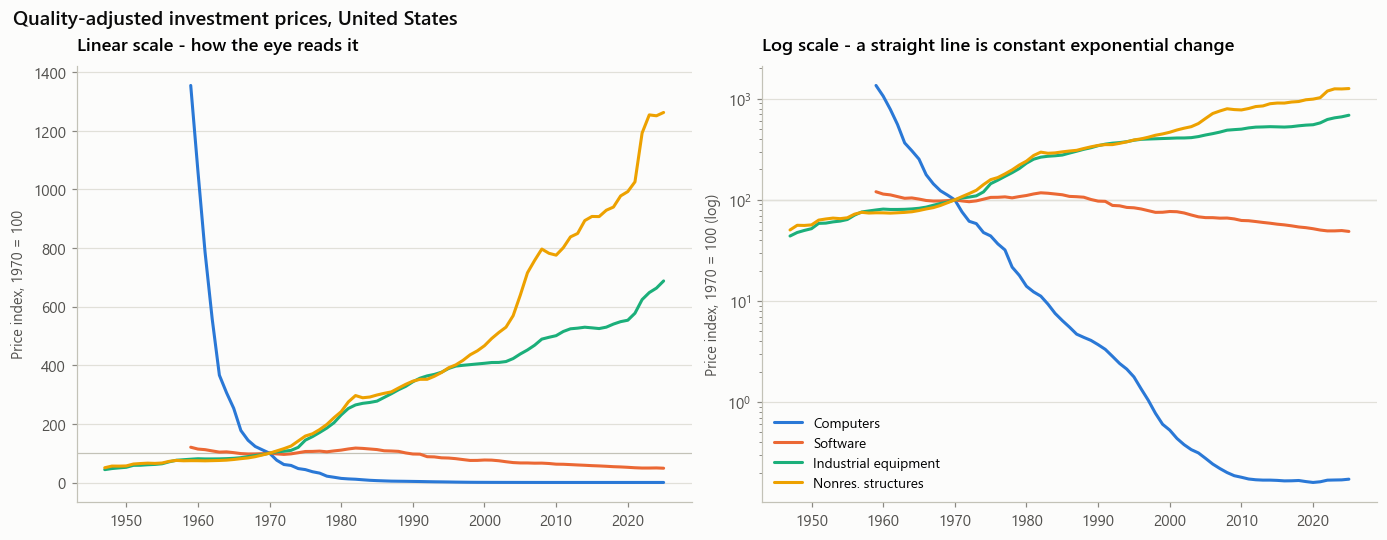

In [12]:
show = ["Computers", "Software", "Industrial equipment", "Nonres. structures"]
colors = dict(zip(show, sl.PALETTE[:len(show)]))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
for ax, logscale in zip(axes, [False, True]):
    for name in show:
        s = Pr[name].dropna()
        ax.plot(s.index, s.values, color=colors[name], label=name, lw=2.0)
    if logscale:
        ax.set_yscale("log")
        ax.set_title("Log scale - a straight line is constant exponential change")
        ax.set_ylabel("Price index, %d = 100 (log)" % BASE_YEAR)
    else:
        ax.set_title("Linear scale - how the eye reads it")
        ax.set_ylabel("Price index, %d = 100" % BASE_YEAR)
    ax.set_xlabel("")
    ax.axhline(100, color=sl.INK["axis"], lw=0.8, zorder=0)
axes[1].legend(loc="lower left", ncol=1)
fig.suptitle("Quality-adjusted investment prices, United States",
             x=0.005, ha="left", fontsize=13, fontweight="semibold",
             color=sl.INK["primary"])
sl.save_fig(fig, "fig1_linear_vs_log", DIRS)
plt.show()

## 2. Is it a straight line? Fit ln(price) = a + b*t

`annual_pct` is the compound annual rate implied by the slope; `r2` is
literally "how straight is the line"; `halving_years` is how long a 50% price
cut takes at that rate.

In [13]:
fits = pd.DataFrame([sl.loglinear_fit(Pr[c], c) for c in Pr.columns]).set_index("label")
fits = fits[["start", "end", "n", "annual_pct", "r2", "halving_years"]].round(3)
print(fits.to_string())

                        start   end   n  annual_pct     r2  halving_years
label                                                                    
Computers                1959  2025  67     -13.209  0.952          4.893
Software                 1959  2025  67      -1.324  0.847         52.000
Info processing equip.   1947  2025  79      -3.081  0.832         22.145
Other info equip.        1947  2025  79       0.297  0.035        233.671
Industrial equipment     1947  2025  79       3.687  0.947         19.144
Transportation equip.    1947  2025  79       2.844  0.940         24.715
Nonres. structures       1947  2025  79       4.514  0.981         15.699
Research and dev.        1947  2025  79       3.168  0.963         22.228
All fixed investment     1947  2025  79       2.816  0.925         24.960


## Figure 2 - Computing against everything else

Dividing the computer price index by the GDP deflator strips out general
inflation, leaving the *relative* price of computing power. One series, so no
legend: the title names it.

FRED GDPDEF: 79 obs, 1947-01-01-2025-01-01
saved -> C:\Users\91838\Downloads\Stack_Article\01_second_half_of_the_chessboard\figures\fig2_relative_price_of_computing.png


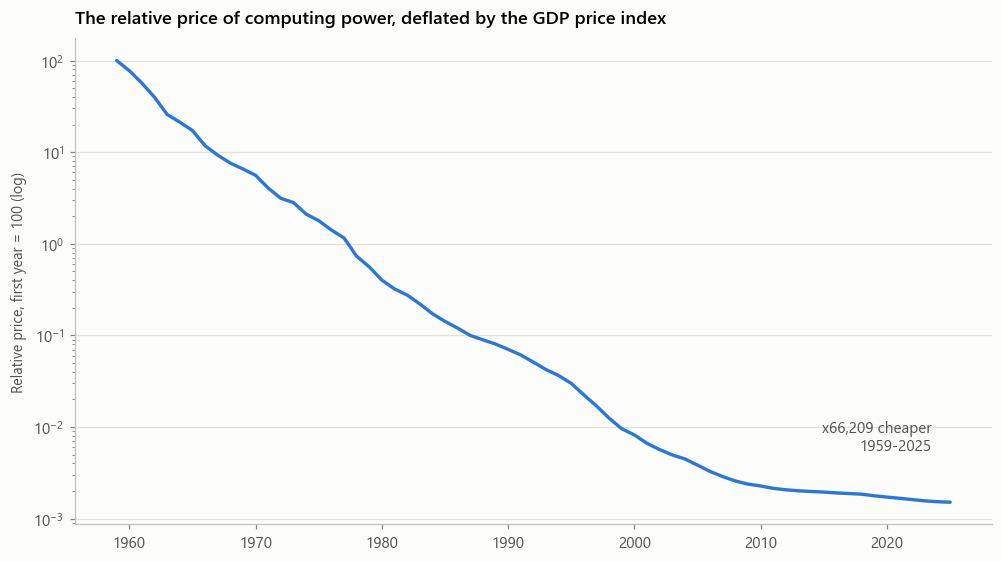

Total fall in relative price: factor of 66209


In [14]:
rel = None
try:
    gdpdef = sl.fred_series("GDPDEF", sl.require(KEYS, "FRED"),
                            cache_dir=DIRS["data"], frequency="a")
    gdpdef_a = gdpdef.groupby(gdpdef.index.year).mean()
    gdpdef_a.index = gdpdef_a.index.astype(int)
    common = P["Computers"].dropna().index.intersection(gdpdef_a.index)
    rel = (P["Computers"].loc[common] / gdpdef_a.loc[common])
    rel = rel / rel.loc[rel.index.min()] * 100.0
except Exception as e:
    print("FRED step skipped (%s). Figure 2 will use the raw price index." % e)
    rel = Pr["Computers"].dropna()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(rel.index, rel.values, color=sl.PALETTE[0], lw=2.2)
ax.set_yscale("log")
ax.set_ylabel("Relative price, first year = 100 (log)")
ax.set_title("The relative price of computing power, deflated by the GDP price index")
fall = rel.iloc[0] / rel.iloc[-1]
ax.annotate("x%s cheaper\n%d-%d" % (format(int(round(fall)), ","), rel.index.min(), rel.index.max()),
            xy=(rel.index[-1], rel.iloc[-1]), xytext=(-12, 34), textcoords="offset points",
            ha="right", color=sl.INK["secondary"], fontsize=10)
sl.save_fig(fig, "fig2_relative_price_of_computing", DIRS)
plt.show()
print("Total fall in relative price: factor of %.0f" % fall)

## Figure 3 - Is the exponent constant?

The book's forward claim depends on the *rate* holding, not just on the level
having fallen. A rolling 10-year annualised rate of change turns that into
something visible: a flat band means a stable exponent, a rising band means the
engine is losing power. Watch the mid-2000s.

saved -> C:\Users\91838\Downloads\Stack_Article\01_second_half_of_the_chessboard\figures\fig3_rolling_rate.png


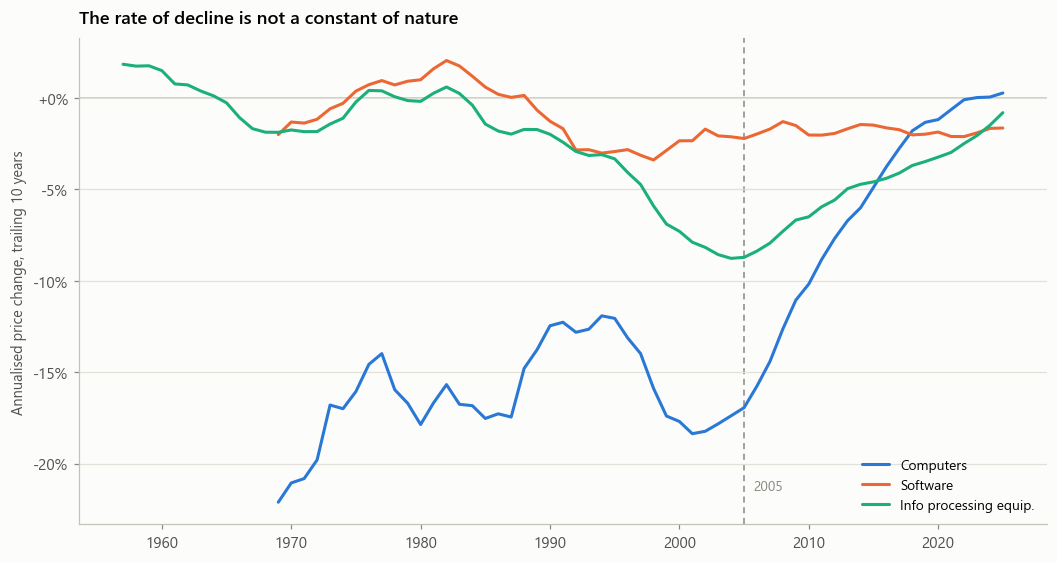

In [15]:
def rolling_rate(s, window=10):
    s = s.dropna()
    return (np.power(s / s.shift(window), 1.0 / window) - 1.0).dropna() * 100

roll_show = ["Computers", "Software", "Info processing equip."]
fig, ax = plt.subplots(figsize=(9.5, 5))
for name, color in zip(roll_show, sl.PALETTE[:3]):
    r = rolling_rate(Pr[name])
    ax.plot(r.index, r.values, color=color, lw=2.0, label=name)
ax.axhline(0, color=sl.INK["axis"], lw=1.0, zorder=0)
ax.axvline(BREAK_YEAR, color=sl.INK["muted"], lw=1.0, ls=(0, (4, 3)), zorder=0)
ax.text(BREAK_YEAR + 0.7, ax.get_ylim()[0] * 0.92, str(BREAK_YEAR),
        color=sl.INK["muted"], fontsize=9)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%+.0f%%" % v))
ax.set_ylabel("Annualised price change, trailing 10 years")
ax.set_title("The rate of decline is not a constant of nature")
ax.legend(loc="lower right")
sl.save_fig(fig, "fig3_rolling_rate", DIRS)
plt.show()

In [ ]:
breaks = {c: sl.chow_test(Pr[c], BREAK_YEAR) for c in roll_show}
print(pd.DataFrame(breaks).T.to_string())

## Figure 4 - Which square are we on?

Every halving of the price is one doubling of power per dollar - one square of
the chessboard. Cumulative halvings since the start of the series answers the
chapter's question literally: how far along the board has the grain actually
piled up, and is it still moving one square at a time?

saved -> C:\Users\91838\Downloads\Stack_Article\01_second_half_of_the_chessboard\figures\fig4_chessboard_squares.png


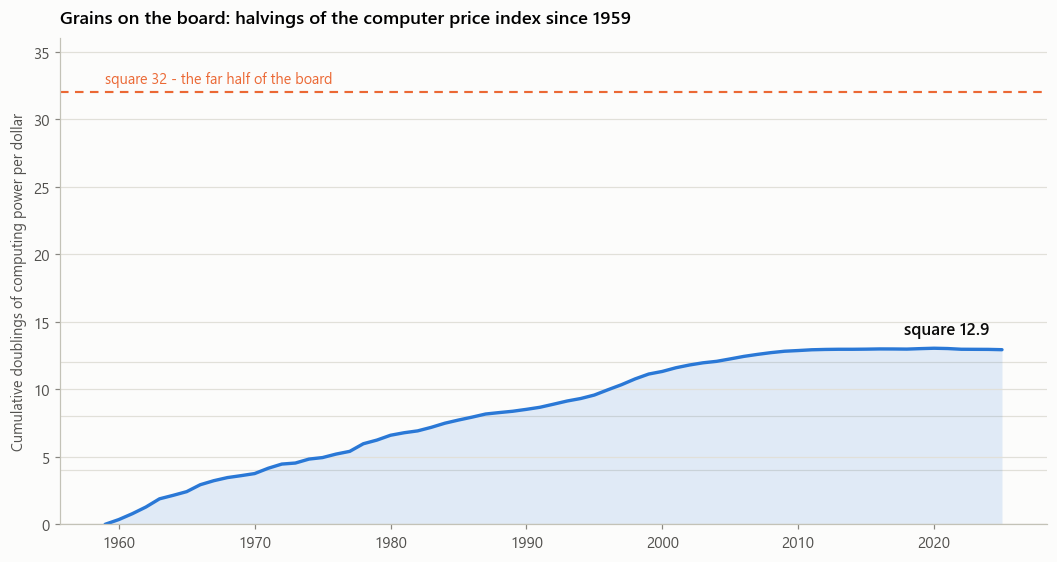

Halvings banked since 1959: 12.94  (a factor of 7.85e+03)


In [16]:
c = P["Computers"].dropna()
halvings = np.log2(c.iloc[0] / c)
sq = float(halvings.iloc[-1])

fig, ax = plt.subplots(figsize=(9.5, 5))
ax.fill_between(halvings.index, 0, halvings.values, color=sl.PALETTE[0], alpha=0.13, lw=0)
ax.plot(halvings.index, halvings.values, color=sl.PALETTE[0], lw=2.2)
for k in range(0, int(np.floor(sq)) + 1, 4):
    ax.axhline(k, color=sl.INK["grid"], lw=0.8, zorder=0)
ax.axhline(32, color=sl.PALETTE[1], lw=1.4, ls=(0, (4, 3)))
ax.text(halvings.index.min(), 32.4, "square 32 - the far half of the board",
        color=sl.PALETTE[1], fontsize=9.5, va="bottom")
ax.set_ylim(0, max(36, sq * 1.15))
ax.set_ylabel("Cumulative doublings of computing power per dollar")
ax.set_title("Grains on the board: halvings of the computer price index since %d" % int(c.index.min()))
ax.annotate("square %.1f" % sq, xy=(halvings.index[-1], sq), xytext=(-8, 10),
            textcoords="offset points", ha="right", color=sl.INK["primary"],
            fontsize=11, fontweight="semibold")
sl.save_fig(fig, "fig4_chessboard_squares", DIRS)
plt.show()
print("Halvings banked since %d: %.2f  (a factor of %.3g)" % (int(c.index.min()), sq, 2 ** sq))

## Figure 5 - Did quantity answer?

A price collapse is only economically interesting if somebody bought the
cheaper thing. Plotting real investment quantity against relative price on
log-log axes traces out a demand relation; the fitted slope is an elasticity.
This is a first, crude look at a curve Ideas 9 and 11 will need properly.

C:\Users\91838\AppData\Local\Temp\ipykernel_33580\688412021.py:4: RuntimeWarning: divide by zero encountered in log
  y = np.log(Qr["Computers"].loc[idx].values)
C:\Users\91838\AppData\Local\Temp\ipykernel_33580\688412021.py:7: RuntimeWarning: invalid value encountered in subtract
  r2 = 1 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2)


saved -> C:\Users\91838\Downloads\Stack_Article\01_second_half_of_the_chessboard\figures\fig5_price_vs_quantity.png


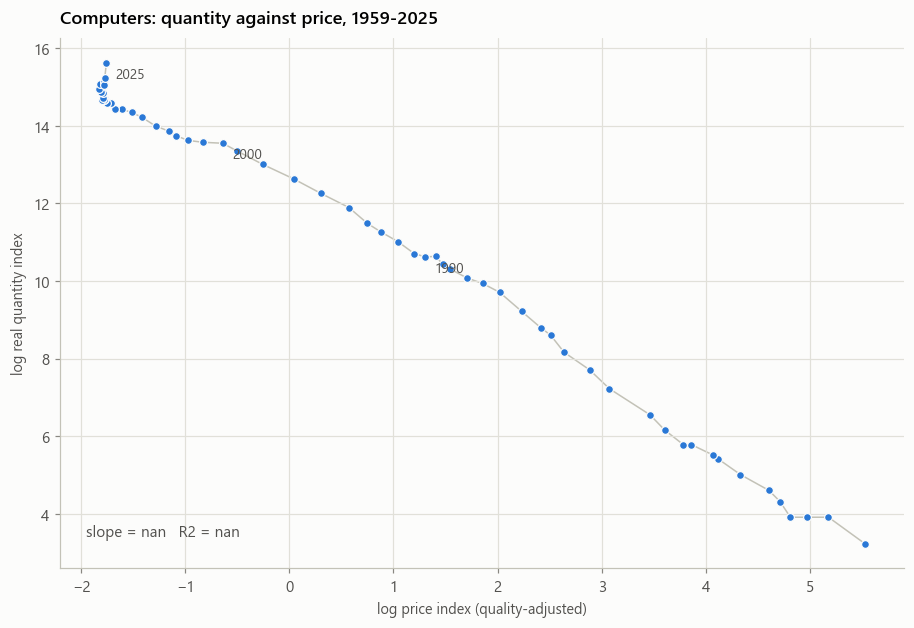

log-log slope (implied demand elasticity): nan


In [17]:
if "Computers" in Qr.columns:
    idx = Pr["Computers"].dropna().index.intersection(Qr["Computers"].dropna().index)
    x = np.log(Pr["Computers"].loc[idx].values)
    y = np.log(Qr["Computers"].loc[idx].values)
    slope, intercept = np.polyfit(x, y, 1)
    yhat = intercept + slope * x
    r2 = 1 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2)

    fig, ax = plt.subplots(figsize=(8.2, 5.6))
    ax.plot(x, y, color=sl.INK["axis"], lw=1.0, zorder=1)
    ax.scatter(x, y, s=26, color=sl.PALETTE[0], zorder=2, linewidths=0.8,
               edgecolors=sl.INK["surface"])
    order = np.argsort(x)
    ax.plot(x[order], yhat[order], color=sl.PALETTE[1], lw=1.8, ls=(0, (5, 3)), zorder=3)
    for yr in [idx.min(), 1990, 2000, int(idx.max())]:
        if yr in idx:
            i = list(idx).index(yr)
            ax.annotate(str(yr), (x[i], y[i]), xytext=(6, -10), textcoords="offset points",
                        fontsize=9, color=sl.INK["secondary"])
    ax.set_xlabel("log price index (quality-adjusted)")
    ax.set_ylabel("log real quantity index")
    ax.set_title("Computers: quantity against price, %d-%d" % (idx.min(), idx.max()))
    ax.annotate("slope = %.2f   R2 = %.2f" % (slope, r2), xy=(0.03, 0.06),
                xycoords="axes fraction", color=sl.INK["secondary"], fontsize=10)
    ax.grid(axis="x")
    sl.save_fig(fig, "fig5_price_vs_quantity", DIRS)
    plt.show()
    print("log-log slope (implied demand elasticity): %.3f" % slope)
else:
    slope, r2 = float("nan"), float("nan")
    print("Quantity index unavailable; skipping Figure 5.")

## 3. Bank the numbers

Everything the write-up will quote gets written to `findings/` so the prose
cites this run rather than my memory.

In [19]:
# --- bank the numbers ------------------------------------------------------
# Self-healing: recompute anything an earlier cell did not leave behind, so a
# skipped cell costs a recomputation rather than a NameError.

if "breaks" not in dir() or not isinstance(globals().get("breaks"), dict):
    roll_show = globals().get("roll_show",
                              ["Computers", "Software", "Info processing equip."])
    breaks = {c: sl.chow_test(Pr[c], BREAK_YEAR) for c in roll_show if c in Pr.columns}
    print("recomputed Chow tests for:", ", ".join(breaks))
    print(pd.DataFrame(breaks).T.to_string())

if "c" not in dir() or not isinstance(globals().get("c"), pd.Series):
    c = P["Computers"].dropna()
if "sq" not in dir():
    sq = float(np.log2(c.iloc[0] / c).iloc[-1])
if "rel" not in dir():
    rel = Pr["Computers"].dropna()
    print("NOTE  Figure 2 did not run; 'rel' falls back to the undeflated index.")
if "fall" not in dir():
    fall = float(rel.iloc[0] / rel.iloc[-1])
if "slope" not in dir():
    slope, r2 = float("nan"), float("nan")

payload = {
    "stacklib_version": sl.__version__,
    "base_year": BASE_YEAR,
    "break_year_tested": BREAK_YEAR,
    "loglinear_fits": fits.reset_index().to_dict(orient="records"),
    "chow_tests": breaks,
    "relative_price_fall_factor": float(fall),
    "relative_price_window": [int(rel.index.min()), int(rel.index.max())],
    "halvings_banked": float(sq),
    "halvings_window": [int(c.index.min()), int(c.index.max())],
    "power_per_dollar_factor": float(2 ** sq),
    "price_quantity_slope": float(slope),
    "price_quantity_r2": float(r2),
    "last_year_in_price_table": int(P.index.max()),
    "series_used": {k: int(v) for k, v in LINES.items()},
}
sl.write_findings(payload, DIRS)
fits.to_csv(pathlib.Path(DIRS["findings"]) / "loglinear_fits.csv")
Pr.to_csv(pathlib.Path(DIRS["data"]) / "price_indexes_rebased.csv")
pd.DataFrame(breaks).T.to_csv(pathlib.Path(DIRS["findings"]) / "chow_tests.csv")
print("\nDone. Figures in figures/, numbers in findings/.")

recomputed Chow tests for: Computers, Software, Info processing equip.
                         break           F     n  pre_annual_pct  post_annual_pct             p
Computers               2005.0  353.135029  67.0      -16.080526        -1.271486  1.110223e-16
Software                2005.0   17.447618  67.0       -0.867453        -1.819920  9.337665e-07
Info processing equip.  2005.0   49.641003  79.0       -1.869213        -2.732339  1.854072e-14
findings -> C:\Users\91838\Downloads\Stack_Article\01_second_half_of_the_chessboard\findings\headline_numbers.json

Done. Figures in figures/, numbers in findings/.


## Caveats to carry into the prose

1. **Hedonic indexes are estimates, not observations.** BEA infers quality
   adjustment from a model. Byrne, Oliner and Sichel have argued the post-2004
   computer deflator understates real quality gains, which would mean Figure 3's
   slowdown is partly a measurement artefact. The honest sentence is "the
   measured rate slowed," not "progress slowed."
2. **Prices are inputs, not outcomes.** Cheap computing is the bounty's
   precondition; Ideas 3-6 test whether it showed up in productivity and income.
3. **The elasticity in Figure 5 is descriptive.** It is a scatter of equilibrium
   outcomes, not an identified demand curve - supply moved too.

**Send back:** the five PNGs, the printed fit table, the Chow output, and
`findings/headline_numbers.json`. I'll write the technical summary from those.